# Modelado · Créditos vehiculares
**Tarea 4 del reto · Soporte 4 · Rol: Ciencia de datos · CRISP-ML(Q) fase 3**

Este notebook documenta paso a paso el **entrenamiento, la prueba y la evaluación** de los modelos y agrega dos pruebas de robustez. Reutiliza las funciones de `modelado.py` (mismas semillas, mismos resultados). Los archivos que usa el tablero (`.pkl`, `config_modelos.json`, predicciones) los genera `python modelado.py`.

| Etapa | Entrena con | Evalúa en | Para qué |
|---|---|---|---|
| A · Ajuste | Agosto | Septiembre | Elegir variables e hiperparámetros |
| B · Prueba | Agosto + septiembre | **Octubre** (una sola vez) | Resultados que se reportan |
| C · Producción | Agosto – octubre | Noviembre (sin etiqueta) | Modelo del tablero |

| Pregunta | Modelo | Por qué |
|---|---|---|
| PE1 Ventas | Gradient boosting (HistGradientBoosting) | Mejor ordenamiento de clientes |
| PE2 Riesgo | Regresión logística | Explicable con coeficientes |
| Comparación | Random Forest | Alternativa de árboles |
| Referencias | Trivial y regla del buró | CML1 |

In [1]:
import os, sys, json, itertools, time, warnings
import numpy as np
import pandas as pd
sys.path.insert(0, os.path.abspath("."))
import modelado as m            # funciones: construir, probar, metricas, regla_buro, aprobados_al
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
prep, ing = m.prep, m.ing
LIMITE, APROBACION = m.LIMITE, m.APROBACION
TABLAS = os.path.join("salidas", "tablas")
os.makedirs(TABLAS, exist_ok=True)
print(f"Meta CN2: impago de los aprobados < {LIMITE:.2%} · Meta CN1: aprobar >= {APROBACION:.0%}")

Meta CN2: impago de los aprobados < 21.71% · Meta CN1: aprobar >= 90%


## 0 · Datos limpios (versión 1) y partición por tiempo
`BRANCH_ID` y `MANUFACTURER_ID` se leen como texto (igual que en la limpieza). `SUPPLIER_ID` se trae del original solo para probar si aporta.

In [2]:
tipos = {"BRANCH_ID": str, "MANUFACTURER_ID": str}
train = pd.read_csv("../limpieza_datos/datos_v1/train_limpio.csv", dtype=tipos)
crudo = prep.estandarizar_estructura(pd.read_csv("../train.csv"))[["UNIQUEID", "SUPPLIER_ID"]]
train = train.merge(crudo.astype({"SUPPLIER_ID": str}), on="UNIQUEID", how="left", validate="1:1")

y = train["LOAN_DEFAULT"]
ago, sep, octu = train["MES"].eq(8), train["MES"].eq(9), train["MES"].eq(10)
X_ago, y_ago = train[ago], y[ago]
X_sep, y_sep = train[sep], y[sep]
X_as, y_as = train[ago | sep], y[ago | sep]
X_oct, y_oct = train[octu], y[octu]
monto_oct = X_oct["DISBURSED_AMOUNT"]

pd.DataFrame({"créditos": [len(X_ago), len(X_sep), len(X_as), len(X_oct)],
              "impago (%)": [100 * v.mean() for v in (y_ago, y_sep, y_as, y_oct)]},
             index=["Agosto (ajuste)", "Septiembre (ajuste)", "Ago+Sep (entrenamiento)", "Octubre (prueba)"]).round(2)

,créditos,impago (%)
Agosto (ajuste),68002,21.57
Septiembre (ajuste),66788,19.19
Ago+Sep (entrenamiento),134790,20.39
Octubre (prueba),98364,23.51


## 1 · Referencias (CML1): clasificador trivial y regla del buró
La regla del buró usa como probabilidad el impago de cada categoría del buró en agosto-septiembre. Solo puede aprobar categorías completas.

In [3]:
resultados = {}
resultados["Trivial"] = m.metricas(y_oct, np.full(len(y_oct), y_as.mean()), monto_oct)
p_buro, n_buro, puntos_buro = m.regla_buro(X_as["CNS_GRUPO"], y_as, X_oct["CNS_GRUPO"], y_oct)
resultados["Regla buró"] = m.metricas(y_oct, p_buro, monto_oct)
resultados["Regla buró"].update(Max_aprobados_CN2=n_buro, Max_aprob_pct_CN2=n_buro / len(y_oct))
pd.DataFrame(resultados).T[["AUC", "KS", "Max_aprobados_CN2", "Max_aprob_pct_CN2"]].round(4)

,AUC,KS,Max_aprobados_CN2,Max_aprob_pct_CN2
Trivial,0.5,0.0,24248,0.246513
Regla buró,0.554497,0.07445,34467,0.350403


**Interpretación:** la regla del buró apenas supera al azar (AUC 0,554). Para dejar el impago de los aprobados por debajo de 21,71 % solo puede aprobar 34 467 créditos (35 %), porque no distingue entre la mitad de clientes sin historial.

## 2 · Ingeniería de características (ajuste: agosto → septiembre)
Se parte de las 15 variables de la Fase 2 y se prueba agregar: `TIENE_MORA`, `CONSULTO_BURO`, `PROP_MORA` (variables nuevas) y `SUPPLIER_ID` agrupado. Un cambio se acepta solo si el AUC promedio sube al menos 0,002.

In [4]:
filas = []
for nuevas, prov in itertools.product([False, True], [False, True]):
    fila = {"nuevas": nuevas, "SUPPLIER_ID": prov}
    for tipo, params in [("logistica", {"C": 1.0}), ("boosting", {})]:
        _, p = m.probar(tipo, X_ago, y_ago, X_sep, nuevas, prov, **params)
        fila[f"AUC_sep_{tipo}"] = roc_auc_score(y_sep, p)
    fila["AUC_promedio"] = (fila["AUC_sep_logistica"] + fila["AUC_sep_boosting"]) / 2
    filas.append(fila)
variantes = pd.DataFrame(filas)
base = variantes.iloc[0]
mejor = variantes.loc[variantes["AUC_promedio"].idxmax()]
if mejor["AUC_promedio"] - base["AUC_promedio"] < m.MEJORA_MINIMA:
    mejor = base
NUEVAS, PROV = bool(mejor["nuevas"]), bool(mejor["SUPPLIER_ID"])
entrada = m.columnas(NUEVAS, PROV)[0]
print(f"Decisión: variables nuevas = {NUEVAS} · SUPPLIER_ID = {PROV} · {len(entrada)} variables")
variantes.round(4)

Decisión: variables nuevas = False · SUPPLIER_ID = False · 15 variables


,nuevas,SUPPLIER_ID,AUC_sep_logistica,AUC_sep_boosting,AUC_promedio
0,False,False,0.6512,0.6559,0.6535
1,False,True,0.6515,0.6537,0.6526
2,True,False,0.6516,0.6560,0.6538
3,True,True,0.6520,0.6534,0.6527


**Interpretación:** ninguna combinación sube el AUC promedio en 0,002 o más. Las variables nuevas repiten información que ya traen las cuentas en mora y las consultas, y `SUPPLIER_ID` empeora al boosting (sobreajuste por muchas categorías). Se mantienen las **15 variables** de la Fase 2.

## 3 · Hiperparámetros (ajuste: agosto → septiembre, métrica AUC)
Métodos de estimación: regresión logística con regularización L2 y L1, regresión logística sobre WoE (scorecard), gradient boosting con *early stopping* y Random Forest.

In [5]:
rejillas = {
    "logistica": [{"C": c, "l1_ratio": 0.0} for c in (0.01, 0.1, 1.0)]
                 + [{"C": c, "l1_ratio": 1.0, "solver": "liblinear"} for c in (0.01, 0.1, 1.0)],
    "logistica_woe": [{"C": c, "l1_ratio": 0.0} for c in (0.01, 0.1, 1.0)],
    "boosting": [dict(learning_rate=lr, max_leaf_nodes=h, min_samples_leaf=n, l2_regularization=l2)
                 for lr, h, n, l2 in itertools.product((0.05, 0.1), (15, 31), (100, 400), (0.0, 1.0))],
    "bosque": [dict(min_samples_leaf=n, max_features=f) for n in (50, 200) for f in ("sqrt", 0.3)],
}
busqueda = []
for tipo, rejilla in rejillas.items():
    for params in rejilla:
        t0 = time.perf_counter()
        _, p = m.probar(tipo, X_ago, y_ago, X_sep, NUEVAS, PROV, **params)
        busqueda.append({"modelo": tipo, "params": json.dumps(params), "AUC_sep": roc_auc_score(y_sep, p),
                         "segundos": time.perf_counter() - t0})
busqueda = pd.DataFrame(busqueda)
mejores = {t: json.loads(g.loc[g["AUC_sep"].idxmax(), "params"]) for t, g in busqueda.groupby("modelo")}
auc_tipo = busqueda.groupby("modelo")["AUC_sep"].max()
RIESGO = "logistica_woe" if auc_tipo["logistica_woe"] > auc_tipo["logistica"] else "logistica"
print(f"{len(busqueda)} modelos entrenados en {busqueda['segundos'].sum():.0f} s")
print("Regresión logística para Riesgo:", RIESGO)
print(json.dumps(mejores, indent=1))
busqueda.sort_values("AUC_sep", ascending=False).groupby("modelo").head(3).round(4)

29 modelos entrenados en 104 s
Regresión logística para Riesgo: logistica
{
 "boosting": {
  "learning_rate": 0.05,
  "max_leaf_nodes": 15,
  "min_samples_leaf": 100,
  "l2_regularization": 0.0
 },
 "bosque": {
  "min_samples_leaf": 50,
  "max_features": 0.3
 },
 "logistica": {
  "C": 0.1,
  "l1_ratio": 0.0
 },
 "logistica_woe": {
  "C": 1.0,
  "l1_ratio": 0.0
 }
}


,modelo,params,AUC_sep,segundos
9,boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15, ...",0.6578,1.7010
14,boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31, ...",0.6577,4.6276
20,boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15, ""...",0.6576,2.6912
1,logistica,"{""C"": 0.1, ""l1_ratio"": 0.0}",0.6515,2.0399
5,logistica,"{""C"": 1.0, ""l1_ratio"": 1.0, ""solver"": ""libline...",0.6514,11.4162
2,logistica,"{""C"": 1.0, ""l1_ratio"": 0.0}",0.6512,2.7180
8,logistica_woe,"{""C"": 1.0, ""l1_ratio"": 0.0}",0.6403,0.5500
26,bosque,"{""min_samples_leaf"": 50, ""max_features"": 0.3}",0.6401,8.0664
7,logistica_woe,"{""C"": 0.1, ""l1_ratio"": 0.0}",0.6396,0.6041
25,bosque,"{""min_samples_leaf"": 50, ""max_features"": ""sqrt""}",0.6392,7.5195


**Interpretación:** el boosting más conservador (tasa de aprendizaje 0,05, 15 hojas) fue el mejor: más complejidad no mejora porque el modelo empieza a memorizar. En la regresión logística, L1 y L2 empatan con C = 0,1 – 1; la versión WoE queda por debajo (0,640 frente a 0,652), por eso Riesgo usa la versión one-hot. Las diferencias entre configuraciones son de milésimas: el límite lo pone la señal de los datos.

## 4 · Prueba final: entrena con agosto + septiembre, evalúa en octubre (CML1, CML2)

In [6]:
nombres = {"logistica": "Logística one-hot", "logistica_woe": "Logística WoE",
           "boosting": "Gradient boosting", "bosque": "Random Forest"}
modelos_oct, probs = {}, {"Regla buró": p_buro}
for tipo, nombre in nombres.items():
    modelos_oct[tipo], probs[nombre] = m.probar(tipo, X_as, y_as, X_oct, NUEVAS, PROV, **mejores[tipo])
    resultados[nombre] = m.metricas(y_oct, probs[nombre], monto_oct)
for tipo in ["boosting", RIESGO]:                     # calibración sigmoide (CML2)
    base_modelo, _ = m.construir(tipo, NUEVAS, PROV, **mejores[tipo])
    cal = CalibratedClassifierCV(base_modelo, method="sigmoid", cv=3).fit(X_as[entrada], y_as)
    probs[nombres[tipo] + " calibrada"] = cal.predict_proba(X_oct[entrada])[:, 1]
    resultados[nombres[tipo] + " calibrada"] = m.metricas(y_oct, probs[nombres[tipo] + " calibrada"], monto_oct)
comparacion = pd.DataFrame(resultados).T
comparacion[["AUC", "PR_AUC", "KS", "Brier", "Prob_media", "Impago_aprobados_90", "Cumple_CN2",
             "Impagos_evitados", "Buenos_rechazados", "Monto_evitado_CE1", "Max_aprobados_CN2"]].round(4)

,AUC,PR_AUC,KS,Brier,Prob_media,Impago_aprobados_90,Cumple_CN2,Impagos_evitados,Buenos_rechazados,Monto_evitado_CE1,Max_aprobados_CN2
Trivial,0.5,0.235147,0.0,0.180831,0.20388,0.233395,False,2468,7368,141383158.0,24248
Regla buró,0.554497,0.263218,0.07445,0.179644,0.203759,0.226245,False,3101,6735,182172067.0,34467
Logística one-hot,0.638957,0.337865,0.203576,0.173406,0.201166,0.217163,False,3905,5931,238813228.0,88494
Logística WoE,0.63104,0.32815,0.190177,0.174294,0.201033,0.21862,False,3776,6060,226000628.0,87428
Gradient boosting,0.647813,0.344855,0.217687,0.17263,0.198003,0.21696,True,3923,5913,237111562.0,88663
Random Forest,0.634893,0.334156,0.196789,0.173841,0.202395,0.218191,False,3814,6022,234841552.0,87790
Gradient boosting calibrada,0.64748,0.346233,0.215223,0.17281,0.198128,0.216632,True,3952,5884,240479880.0,88821
Logística one-hot calibrada,0.638222,0.337448,0.201908,0.173643,0.199953,0.217445,False,3880,5956,236901694.0,88205


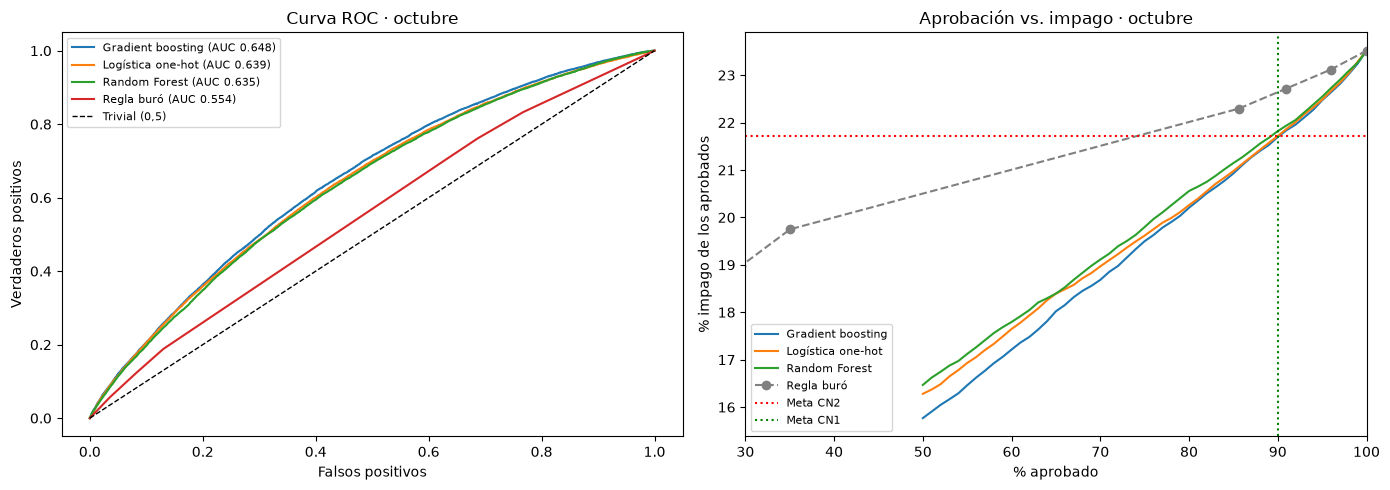

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nombre in ["Gradient boosting", nombres[RIESGO], "Random Forest", "Regla buró"]:
    fpr, tpr, _ = roc_curve(y_oct, probs[nombre])
    ax[0].plot(fpr, tpr, label=f"{nombre} (AUC {resultados[nombre]['AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Trivial (0,5)")
ax[0].set(xlabel="Falsos positivos", ylabel="Verdaderos positivos", title="Curva ROC · octubre"); ax[0].legend(fontsize=8)

tasas = np.round(np.arange(0.50, 1.0001, 0.01), 2)
for nombre in ["Gradient boosting", nombres[RIESGO], "Random Forest"]:
    ax[1].plot(tasas * 100, [100 * y_oct.to_numpy()[m.aprobados_al(probs[nombre], t)].mean() for t in tasas], label=nombre)
ax[1].plot([100 * x for _, x, _ in puntos_buro], [100 * z for _, _, z in puntos_buro], "o--", color="gray", label="Regla buró")
ax[1].axhline(LIMITE * 100, color="red", ls=":", label="Meta CN2"); ax[1].axvline(90, color="green", ls=":", label="Meta CN1")
ax[1].set(xlabel="% aprobado", ylabel="% impago de los aprobados", title="Aprobación vs. impago · octubre", xlim=(30, 100))
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretación:**
- **ROC:** los tres modelos están juntos (AUC 0,635 – 0,648) y muy por encima de la regla del buró, que casi coincide con la diagonal del azar.
- **Aprobación vs. impago (gráfico clave):** para cualquier % de aprobación, los modelos tienen menos impago que la regla. La regla llega a la meta solo aprobando el 35 %; el gradient boosting la alcanza aprobando el 90 % (21,70 %). Aprobando el 50 % el impago bajaría a cerca de 15,8 %.
- Con el mismo límite de impago, el modelo aprueba 88 663 créditos frente a 34 467 de la regla: **54 196 clientes viables más** (PE1).

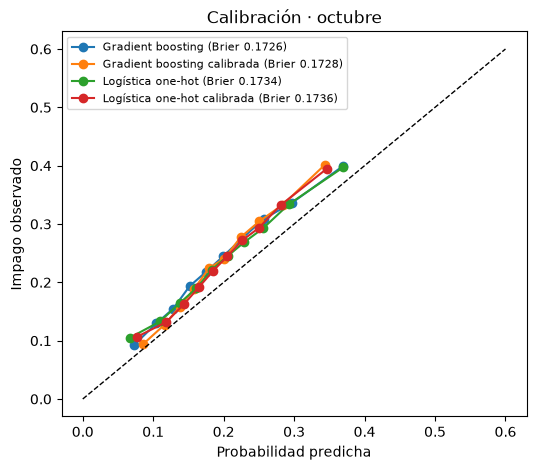

Probabilidad media predicha (boosting): 19.80% · impago real: 23.51%


In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
for nombre in ["Gradient boosting", "Gradient boosting calibrada", nombres[RIESGO], nombres[RIESGO] + " calibrada"]:
    frac, media = calibration_curve(y_oct, probs[nombre], n_bins=10, strategy="quantile")
    ax.plot(media, frac, "o-", label=f"{nombre} (Brier {resultados[nombre]['Brier']:.4f})")
ax.plot([0, 0.6], [0, 0.6], "k--", lw=1)
ax.set(xlabel="Probabilidad predicha", ylabel="Impago observado", title="Calibración · octubre"); ax.legend(fontsize=8); plt.show()
print(f"Probabilidad media predicha (boosting): {probs['Gradient boosting'].mean():.2%} · impago real: {y_oct.mean():.2%}")

**Interpretación:** todos los puntos quedan por encima de la diagonal: el modelo **subestima el riesgo unos 3 a 4 puntos** en octubre (predice 19,8 % en promedio; el real fue 23,5 %). La curva es recta y paralela a la diagonal, así que el modelo **ordena bien** a los clientes; lo que falla es el nivel, porque octubre fue un mes con más impago que agosto y septiembre. Calibrar con datos de agosto-septiembre no lo corrige (Brier casi igual). Las decisiones por ranking siguen siendo válidas; la probabilidad absoluta debe leerse como algo optimista.

## 5 · Robustez 1: ¿el cumplimiento de CN2 es sólido? (bootstrap)
Se remuestrean los créditos de octubre 1 000 veces (con reemplazo), manteniendo el corte del modelo, para estimar el intervalo de confianza del 95 % del impago de los aprobados y del AUC.

In [9]:
rng = np.random.default_rng(m.SEMILLA)
y_arr, n = y_oct.to_numpy(), len(y_oct)
B, B_AUC = 1000, 200
muestras = [rng.integers(0, n, n) for _ in range(B)]
filas = []
for nombre in ["Gradient boosting", nombres[RIESGO]]:
    p = probs[nombre]
    aucs = [roc_auc_score(y_arr[i], p[i]) for i in muestras[:B_AUC]]
    for tasa in (0.85, 0.88, 0.90):
        aprob = m.aprobados_al(p, tasa)
        imp = np.array([y_arr[i][aprob[i]].mean() for i in muestras])
        filas.append({"modelo": nombre, "% aprobado": int(tasa * 100),
                      "impago aprobados (%)": 100 * y_arr[aprob].mean(),
                      "IC95 inferior (%)": 100 * np.percentile(imp, 2.5),
                      "IC95 superior (%)": 100 * np.percentile(imp, 97.5),
                      "P(impago < meta)": (imp < LIMITE).mean(),
                      "AUC IC95": f"{np.percentile(aucs, 2.5):.3f} – {np.percentile(aucs, 97.5):.3f}"})
robustez = pd.DataFrame(filas)
robustez.to_csv(os.path.join(TABLAS, "robustez_bootstrap.csv"), index=False)
robustez.round(3)

,modelo,% aprobado,impago aprobados (%),IC95 inferior (%),IC95 superior (%),P(impago < meta),AUC IC95
0,Gradient boosting,85,20.927,20.648,21.216,1.000,0.644 – 0.652
1,Gradient boosting,88,21.402,21.127,21.690,0.981,0.644 – 0.652
2,Gradient boosting,90,21.696,21.425,21.973,0.523,0.644 – 0.652
3,Logística one-hot,85,20.977,20.690,21.263,1.000,0.635 – 0.643
4,Logística one-hot,88,21.426,21.142,21.710,0.974,0.635 – 0.643
5,Logística one-hot,90,21.716,21.433,22.012,0.454,0.635 – 0.643


**Interpretación:**
- **Aprobando el 90 %**, el impago de los aprobados (21,70 %) tiene un intervalo de 95 % entre **21,43 % y 21,97 %**, y la meta (21,71 %) cae justo en el medio: la probabilidad de cumplir CN2 es **52 %** con gradient boosting y 45 % con regresión logística. **Al 90 % el cumplimiento es un empate estadístico, no es sólido.**
- **Aprobando el 88 %**, el impago baja a 21,40 % (IC 21,13 – 21,69 %) y la probabilidad de cumplir CN2 sube a **98 %**. Aprobando el 85 %, a 100 %.
- El AUC es estable: 0,644 – 0,652 (boosting) y 0,635 – 0,643 (logística); los intervalos casi no se cruzan, así que el boosting sí ordena mejor.

**Consecuencia para el negocio (R2):** CN1 (aprobar ≥ 90 %) y CN2 (impago < 21,71 %) no se pueden cumplir a la vez con seguridad. Recomendación: **aprobar alrededor del 88 %**, que cumple CN2 con 98 % de confianza y conserva casi 9 de cada 10 aprobaciones; la decisión final corresponde a las gerencias.

## 6 · Robustez 2: ¿cuánto depende el modelo de la sucursal y de la edad?
La sucursal es la segunda variable más importante y la edad es sensible (equidad, R11). Se reentrena sin cada una (agosto + septiembre → octubre) para medir cuánto se pierde.

In [10]:
def probar_sin(tipo, quitar):
    """Entrena quitando variables (modifica temporalmente las listas de modelado.py)."""
    cat0, num0 = m.CAT_BASE, m.NUM_BASE
    m.CAT_BASE = [c for c in cat0 if c not in quitar]
    m.NUM_BASE = [c for c in num0 if c not in quitar]
    try:
        return m.probar(tipo, X_as, y_as, X_oct, NUEVAS, PROV, **mejores[tipo])[1]
    finally:
        m.CAT_BASE, m.NUM_BASE = cat0, num0

filas = []
for tipo in ["boosting", RIESGO]:
    for etiqueta, quitar in [("Modelo completo (15)", []), ("Sin sucursal", ["BRANCH_ID"]), ("Sin edad", ["EDAD"])]:
        p = probs[nombres[tipo]] if not quitar else probar_sin(tipo, quitar)
        r = m.metricas(y_oct, p, monto_oct)
        filas.append({"modelo": nombres[tipo], "variante": etiqueta, "AUC": r["AUC"], "KS": r["KS"],
                      "impago aprobados 90 (%)": 100 * r["Impago_aprobados_90"],
                      "max aprobados con impago < meta": r["Max_aprobados_CN2"]})
sensibilidad = pd.DataFrame(filas)
sensibilidad.to_csv(os.path.join(TABLAS, "sensibilidad_variables.csv"), index=False)
sensibilidad.round(4)

,modelo,variante,AUC,KS,impago aprobados 90 (%),max aprobados con impago < meta
0,Gradient boosting,Modelo completo (15),0.6478,0.2177,21.6960,88663
1,Gradient boosting,Sin sucursal,0.6290,0.1877,21.8100,87651
2,Gradient boosting,Sin edad,0.6457,0.2131,21.6530,88924
3,Logística one-hot,Modelo completo (15),0.6390,0.2036,21.7163,88494
4,Logística one-hot,Sin sucursal,0.6201,0.1711,21.9196,86717
5,Logística one-hot,Sin edad,0.6371,0.2004,21.7502,88255


**Interpretación:**
- **Sin sucursal** el AUC cae de 0,648 a 0,629 (boosting) y de 0,639 a 0,620 (logística), y al 90 % ya no se cumple CN2 (21,81 %). La sucursal aporta información real que las demás variables no reemplazan; aun sin ella, el modelo sigue muy por encima de la regla del buró (0,554).
- **Sin edad** el AUC casi no cambia (0,648 → 0,646) y el impago de los aprobados incluso queda igual o mejor (21,65 %), con más créditos aprobables (88 924 frente a 88 663).

**Consecuencia (equidad, R11):** la edad aporta muy poco y es una variable sensible. **Se puede quitar sin perder desempeño**, lo que reduce el riesgo de discriminación por edad. Se deja como recomendación para la versión siguiente del modelo; el tablero actual mantiene las 15 variables evaluadas.

## 7 · Explicabilidad: coeficientes (Riesgo) e importancia de variables (Ventas)

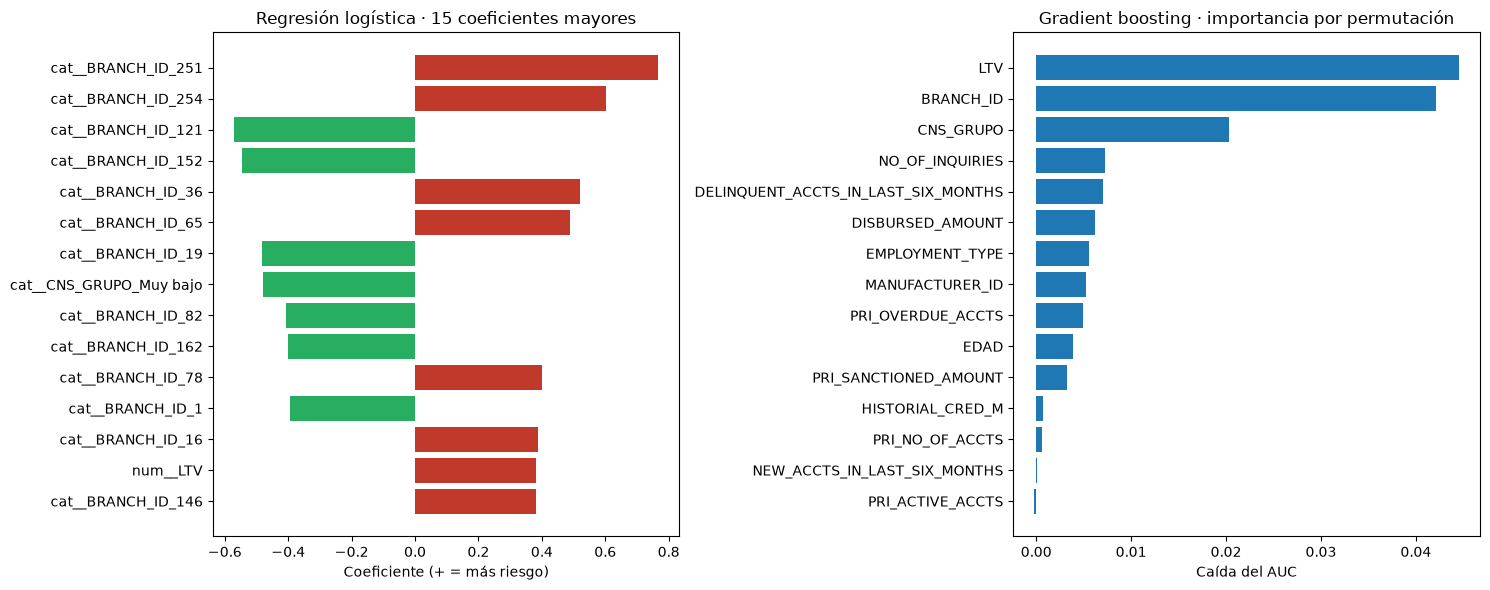

,variable,coeficiente,odds_ratio
59,cat__BRANCH_ID_251,0.767,2.154
60,cat__BRANCH_ID_254,0.601,1.825
31,cat__BRANCH_ID_121,-0.571,0.565
42,cat__BRANCH_ID_152,-0.547,0.579
70,cat__BRANCH_ID_36,0.520,1.682
79,cat__BRANCH_ID_65,0.490,1.632
51,cat__BRANCH_ID_19,-0.484,0.617
15,cat__CNS_GRUPO_Muy bajo,-0.479,0.619
94,cat__BRANCH_ID_82,-0.406,0.666
47,cat__BRANCH_ID_162,-0.400,0.670


In [11]:
lr = modelos_oct[RIESGO]
nombres_lr = lr[:-1].transform(X_oct[entrada].head(5)).columns
coef = pd.DataFrame({"variable": nombres_lr, "coeficiente": lr.named_steps["modelo"].coef_[0]})
coef["odds_ratio"] = np.exp(coef["coeficiente"])
coef = coef.reindex(coef["coeficiente"].abs().sort_values(ascending=False).index)

muestra = X_oct.sample(n=20000, random_state=m.SEMILLA)
imp = permutation_importance(modelos_oct["boosting"], muestra[entrada], y_oct.loc[muestra.index],
                             scoring="roc_auc", n_repeats=5, random_state=m.SEMILLA, n_jobs=1)
importancia = pd.DataFrame({"variable": entrada, "caida_AUC": imp.importances_mean}).sort_values("caida_AUC")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
top = coef.head(15).iloc[::-1]
ax[0].barh(top["variable"], top["coeficiente"], color=np.where(top["coeficiente"] > 0, "#c0392b", "#27ae60"))
ax[0].set(title="Regresión logística · 15 coeficientes mayores", xlabel="Coeficiente (+ = más riesgo)")
ax[1].barh(importancia["variable"], importancia["caida_AUC"])
ax[1].set(title="Gradient boosting · importancia por permutación", xlabel="Caída del AUC")
plt.tight_layout(); plt.show()
coef.head(10).round(3)

**Interpretación:** en el gradient boosting, **LTV, sucursal y categoría del buró** explican la mayor parte de la capacidad predictiva; historial, cuentas nuevas y cuentas activas casi no aportan una vez que están las demás. En la regresión logística, los coeficientes más grandes son sucursales (la 251 multiplica las odds de impago por 2,2; la 121 las reduce a la mitad), seguidas de "buró muy bajo" (protege) y LTV (más financiamiento, más riesgo). Son asociaciones: no prueban que una sucursal gestione peor.

## 8 · Equidad (R11): desempeño por edad y tipo de empleo

In [12]:
seg = X_oct.assign(GRUPO_EDAD=pd.cut(X_oct["EDAD"], [0, 25, 30, 35, 45, 120],
                                     labels=["18-25", "26-30", "31-35", "36-45", "46+"]))
aprob = m.aprobados_al(probs["Gradient boosting"], APROBACION)
filas = []
for col in ["GRUPO_EDAD", "EMPLOYMENT_TYPE"]:
    for g, idx in seg.groupby(col, observed=True).indices.items():
        yy = y_oct.to_numpy()[idx]
        filas.append({"segmento": col, "grupo": g, "créditos": len(idx), "impago real (%)": 100 * yy.mean(),
                      "AUC": roc_auc_score(yy, probs["Gradient boosting"][idx]),
                      "% aprobado": 100 * aprob[idx].mean(), "impago aprobados (%)": 100 * yy[aprob[idx]].mean()})
pd.DataFrame(filas).round(2)

,segmento,grupo,créditos,impago real (%),AUC,% aprobado,impago aprobados (%)
0,GRUPO_EDAD,18-25,23078,25.44,0.63,88.21,23.43
1,GRUPO_EDAD,26-30,19608,24.17,0.64,89.19,22.26
2,GRUPO_EDAD,31-35,16394,23.87,0.65,89.86,21.99
3,GRUPO_EDAD,36-45,24382,22.12,0.65,91.35,20.53
4,GRUPO_EDAD,46+,14902,21.55,0.67,91.79,19.98
5,EMPLOYMENT_TYPE,Salaried,40420,22.14,0.65,91.95,20.71
6,EMPLOYMENT_TYPE,Self employed,54373,24.56,0.65,88.51,22.45
7,EMPLOYMENT_TYPE,Sin dato,3571,23.19,0.62,90.65,21.84


**Interpretación:** los jóvenes de 18 a 25 años y los independientes tienen más impago real y el modelo les aprueba algo menos (88 % frente a 92 % de los mayores de 46). El AUC es menor en los jóvenes (0,63 frente a 0,67): el modelo los distingue peor. La diferencia es moderada y se explica por el impago real de cada grupo; como la edad casi no aporta (sección 6), quitarla es la forma más simple de reducir este riesgo.

## Conclusiones del modelado
1. **Modelo elegido:** gradient boosting para Ventas (AUC 0,648, Gini 0,30, KS 0,218) y regresión logística para Riesgo (AUC 0,639), por explicable. Los cuatro enfoques llegan al mismo techo (0,63 – 0,65): el límite lo pone la señal de los datos (la mitad sin historial y sin datos de ingreso), no el algoritmo.
2. **Frente a la referencia:** el modelo tiene 2,7 veces el poder de discriminación de la regla del buró (Gini 0,30 frente a 0,11) y, con el mismo límite de impago, aprueba **88 663 créditos frente a 34 467** (+54 196 clientes viables, PE1).
3. **Impacto en octubre:** baja el impago de los aprobados de 23,51 % a 21,70 % rechazando el 10 % más riesgoso: 3 923 impagos evitados y 237 millones desembolsados a clientes que no pagaron (PE2, CE1).
4. **Robustez:** al 90 % de aprobación el cumplimiento de CN2 es un empate estadístico (52 %); **al 88 % se cumple con 98 % de confianza**. Se recomienda un corte cercano al 88 %.
5. **Limitaciones:** el modelo subestima el nivel de riesgo en meses malos (calibración), depende de la sucursal (asociación, no causa), solo se observa la primera cuota y solo hay créditos aprobados.